# Linear Model Feature Combination Analysis (Anchor-level)

This notebook evaluates **logistic regression** models using five similarity features:

- DTW similarity
- OT similarity
- Centroid similarity
- Area similarity
- Aspect Ratio similarity

Evaluation is done at **anchor level** (GroupKFold grouped by `anchor_id`) and reports:
- Recall@1
- Mean Rank / Median Rank
- Score statistics for top-1 predictions


In [20]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold

from itertools import combinations

%matplotlib inline

# Plot settings (kept consistent with your script, but notebook-friendly)
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["font.size"] = 9
plt.rcParams["axes.linewidth"] = 0.5
plt.rcParams["xtick.major.width"] = 0.5
plt.rcParams["ytick.major.width"] = 0.5
plt.rcParams["figure.dpi"] = 300
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42

In [21]:
from cell_matching_utils import (
    load_cells_from_csv_files,
    dtw_distance_gpu_single,
    get_cluster_cells,
    compute_ot_cost_matrix,
    solve_optimal_transport,
    DTW_NORM_DIVISOR,
    OT_NORM_DIVISOR,
    CENTROID_NORM_DIVISOR,
    NUM_CONTOUR_POINTS,
)

In [22]:
WINDOW_SIZE = 200

FEATURE_NAMES = [
    "dtw_similarity",
    "ot_similarity",
    "centroid_similarity",
    "area_similarity",
    "aspect_ratio_similarity",
]
FEATURE_DISPLAY_NAMES = ["DTW", "OT", "Centroid", "Area", "Aspect Ratio"]

In [23]:
def uniform_resample_contour(contour, target_num_points):
    """Uniformly resample contour points to a fixed number of points."""
    contour = np.asarray(contour)

    if len(contour) == target_num_points:
        return contour

    # ensure closed contour for stable arc-length sampling
    if len(contour) == 0:
        return np.zeros((target_num_points, 2), dtype=float)

    if not np.allclose(contour[0], contour[-1]):
        contour = np.vstack([contour, contour[0:1]])

    dists = np.sqrt(np.sum(np.diff(contour, axis=0) ** 2, axis=1))
    cumulative = np.concatenate([[0.0], np.cumsum(dists)])
    total_length = cumulative[-1]

    if total_length == 0:
        return np.tile(contour[0], (target_num_points, 1))

    target = np.linspace(0, total_length, target_num_points)

    resampled_x = np.interp(target, cumulative, contour[:, 0])
    resampled_y = np.interp(target, cumulative, contour[:, 1])
    return np.column_stack([resampled_x, resampled_y])


def get_candidates_in_window(anchor, candidates, window_size):
    """Return candidates within a square window centered at anchor centroid."""
    window_half = window_size / 2.0
    cx, cy = anchor.centroid

    out = []
    for cand in candidates:
        cx2, cy2 = cand.centroid
        if abs(cx2 - cx) <= window_half and abs(cy2 - cy) <= window_half:
            out.append(cand)
    return out

In [24]:
def calculate_all_features(cell1, cell2, cells_by_slice):
    """
    Calculate all 5 features as similarity scores (higher is better, range ~[0, 10]).
    """
    features = {}

    # 1) DTW similarity
    try:
        if hasattr(cell1, "contour_points_200") and hasattr(cell2, "contour_points_200"):
            dtw_raw = dtw_distance_gpu_single(cell1.contour_points_200, cell2.contour_points_200)
        else:
            c1 = uniform_resample_contour(cell1.contour_points, NUM_CONTOUR_POINTS)
            c2 = uniform_resample_contour(cell2.contour_points, NUM_CONTOUR_POINTS)
            dtw_raw = dtw_distance_gpu_single(c1, c2)

        dtw_loss = min(10.0, dtw_raw / DTW_NORM_DIVISOR * 10.0)
        features["dtw_similarity"] = 10.0 - dtw_loss
    except Exception:
        features["dtw_similarity"] = 0.0

    # 2) OT similarity
    try:
        cluster1 = get_cluster_cells(cell1, cells_by_slice)
        cluster2 = get_cluster_cells(cell2, cells_by_slice)

        if len(cluster1) == 1 and len(cluster2) == 1:
            features["ot_similarity"] = 10.0
        elif len(cluster1) > 1 and len(cluster2) > 1:
            C = compute_ot_cost_matrix(cluster1, cluster2)
            areas1 = np.array([c.area for c in cluster1])
            areas2 = np.array([c.area for c in cluster2])
            w1 = areas1 / areas1.sum()
            w2 = areas2 / areas2.sum()
            ot_raw, _ = solve_optimal_transport(C, w1, w2)
            ot_loss = min(10.0, ot_raw / OT_NORM_DIVISOR * 10.0)
            features["ot_similarity"] = 10.0 - ot_loss
        else:
            features["ot_similarity"] = 0.0
    except Exception:
        features["ot_similarity"] = 0.0

    # 3) Centroid similarity
    cx1, cy1 = cell1.centroid
    cx2, cy2 = cell2.centroid
    dist = np.sqrt((cx2 - cx1) ** 2 + (cy2 - cy1) ** 2)
    centroid_loss = min(10.0, dist / CENTROID_NORM_DIVISOR * 10.0)
    features["centroid_similarity"] = 10.0 - centroid_loss

    # 4) Area similarity
    a1, a2 = cell1.area, cell2.area
    denom = max(a1, a2)
    ratio = (min(a1, a2) / denom) if denom > 0 else 0.0
    features["area_similarity"] = ratio * 10.0

    # 5) Aspect ratio similarity
    aspect_diff = abs(cell1.aspect_ratio - cell2.aspect_ratio)
    aspect_loss = min(10.0, aspect_diff * 2.5)
    features["aspect_ratio_similarity"] = 10.0 - aspect_loss

    return features

In [25]:
def build_dataset(golden_df, cells_by_slice):
    """Build dataset with 5 similarity features for anchor-level training/evaluation."""
    print("\nBuilding dataset (5 features, window filtering)...")
    samples = []

    for idx, row in golden_df.iterrows():
        if (idx + 1) % 50 == 0:
            print(f"  Processing {idx+1}/{len(golden_df)} pairs...")

        start_layer = row["Start_layer"]
        end_layer = row["End_layer"]
        start_cell_id = row["Start_cell"]
        true_match_id = row["End_cell"]

        # only consecutive slices
        if end_layer - start_layer != 1:
            continue

        # locate anchor
        anchor = None
        for c in cells_by_slice.get(start_layer, []):
            if c.cell_id == start_cell_id:
                anchor = c
                break
        if anchor is None:
            continue

        anchor_id = f"L{start_layer}_{start_cell_id}"

        candidates = cells_by_slice.get(end_layer, [])
        candidates_in_window = get_candidates_in_window(anchor, candidates, WINDOW_SIZE)
        if len(candidates_in_window) == 0:
            continue

        for cand in candidates_in_window:
            feats = calculate_all_features(anchor, cand, cells_by_slice)
            is_true = (cand.cell_id == true_match_id)

            sample = {
                "anchor_id": anchor_id,
                "start_layer": start_layer,
                "end_layer": end_layer,
                "start_cell_id": start_cell_id,
                "candidate_cell_id": cand.cell_id,
                "is_true_match": bool(is_true),
            }
            sample.update(feats)
            samples.append(sample)

    df = pd.DataFrame(samples)
    n_anchors = df["anchor_id"].nunique() if len(df) else 0
    print(f"  Dataset size: {len(df)} samples from {n_anchors} anchors")
    return df

In [26]:
def train_linear_model_with_features(df, feature_subset):
    """
    Train logistic regression using GroupKFold (grouped by anchor_id).
    """
    X = df[feature_subset].values
    y = df["is_true_match"].values.astype(int)
    groups = df["anchor_id"].values

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    model = LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced")

    # Fit on full data once for coefficient sign diagnostics
    model.fit(X_scaled, y)
    print(f"\n  Coefficient diagnostics ({'+'.join([f.replace('_similarity','') for f in feature_subset])}):")
    for name, coef in zip(feature_subset, model.coef_[0]):
        short = name.replace("_similarity", "")
        tag = "positive" if coef > 0 else "negative"
        print(f"    {short:15s}: {coef:+8.4f}  ({tag})")

    # Out-of-fold prediction by GroupKFold
    gkf = GroupKFold(n_splits=5)
    pred = np.zeros(len(y), dtype=float)

    for tr_idx, va_idx in gkf.split(X_scaled, y, groups=groups):
        model.fit(X_scaled[tr_idx], y[tr_idx])
        pred[va_idx] = model.predict_proba(X_scaled[va_idx])[:, 1]

    out = df.copy()
    out["pred_score"] = pred
    return out

In [27]:
def evaluate_anchor_level_performance(df_with_pred, k_values=(1, 3, 5)):
    """Anchor-level Recall@K and rank statistics."""
    y_true = df_with_pred["is_true_match"].values.astype(int)
    y_score = df_with_pred["pred_score"].values
    anchor_ids = df_with_pred["anchor_id"].values

    unique_anchors = df_with_pred["anchor_id"].unique()

    recall_hits = {k: 0 for k in k_values}
    ranks = []
    top1_scores_correct = []
    top1_scores_incorrect = []

    for aid in unique_anchors:
        mask = (anchor_ids == aid)
        labels = y_true[mask]
        scores = y_score[mask]

        if labels.sum() == 0:
            continue

        order = np.argsort(scores)[::-1]

        for k in k_values:
            if labels[order[:k]].sum() > 0:
                recall_hits[k] += 1

        true_local = np.where(labels == 1)[0][0]
        rank = np.where(order == true_local)[0][0] + 1
        ranks.append(rank)

        top1 = order[0]
        if labels[top1] == 1:
            top1_scores_correct.append(scores[top1])
        else:
            top1_scores_incorrect.append(scores[top1])

    num_anchors = len(unique_anchors)

    metrics = {
        "num_anchors": num_anchors,
        "mean_rank": float(np.mean(ranks)) if ranks else 0.0,
        "median_rank": float(np.median(ranks)) if ranks else 0.0,
        "top1_score_correct_mean": float(np.mean(top1_scores_correct)) if top1_scores_correct else 0.0,
        "top1_score_correct_std": float(np.std(top1_scores_correct)) if top1_scores_correct else 0.0,
        "top1_score_incorrect_mean": float(np.mean(top1_scores_incorrect)) if top1_scores_incorrect else 0.0,
        "top1_score_incorrect_std": float(np.std(top1_scores_incorrect)) if top1_scores_incorrect else 0.0,
        "num_correct": int(len(top1_scores_correct)),
        "num_incorrect": int(len(top1_scores_incorrect)),
    }

    for k in k_values:
        metrics[f"Recall@{k}"] = (recall_hits[k] / num_anchors) if num_anchors > 0 else 0.0

    return metrics

In [28]:
def analyze_feature_combination(df, feature_subset, feature_names_display):
    """Train/eval one feature subset and return a flat result dict."""
    df_pred = train_linear_model_with_features(df, feature_subset)
    metrics = evaluate_anchor_level_performance(df_pred, k_values=(1, 3, 5))

    result = {
        "features": "+".join(feature_names_display),
        "num_features": len(feature_subset),
        "Recall@1": metrics["Recall@1"],
        "Recall@3": metrics["Recall@3"],
        "Recall@5": metrics["Recall@5"],
        "mean_rank": metrics["mean_rank"],
        "median_rank": metrics["median_rank"],
        "top1_score_correct_mean": metrics["top1_score_correct_mean"],
        "top1_score_correct_std": metrics["top1_score_correct_std"],
        "top1_score_incorrect_mean": metrics["top1_score_incorrect_mean"],
        "top1_score_incorrect_std": metrics["top1_score_incorrect_std"],
        "score_gap": metrics["top1_score_correct_mean"] - metrics["top1_score_incorrect_mean"],
        "num_correct": metrics["num_correct"],
        "num_incorrect": metrics["num_incorrect"],
    }
    return result

In [29]:
def plot_core_features_performance(results_df, output_dir):
 
    core_configs = [
        ("DTW+OT+Centroid", 3, "Full (3 features)"),
        ("DTW+OT", 2, "DTW+OT only"),
        ("DTW+Centroid", 2, "DTW+Centroid only"),
        ("OT+Centroid", 2, "OT+Centroid only"),
        ("DTW", 1, "DTW only"),
        ("OT", 1, "OT only"),
        ("Centroid", 1, "Centroid only"),
    ]
    colors_map = {3: "#D62246", 2: "#F18F01", 1: "#06A77D"}

    config_results = []
    for name, n_feat, label in core_configs:
        row = results_df[results_df["features"] == name]
        if len(row) == 0:
            continue
        row0 = row.iloc[0]
        config_results.append(
            {
                "label": label,
                "n_features": n_feat,
                "color": colors_map[n_feat],
                "Recall@1": row0["Recall@1"],
                "Recall@3": row0["Recall@3"],
                "mean_rank": row0["mean_rank"],
                "score_gap": row0["score_gap"],
            }
        )

    if len(config_results) == 0:
        print("[WARN] No matching rows found for core_configs; skipping plots.")
        return

    # ---- Figure 1: Recall@1 ----
    fig, ax = plt.subplots(1, 1, figsize=(6, 4.5))

    x = np.arange(len(config_results))
    recalls = [r["Recall@1"] for r in config_results]
    colors = [r["color"] for r in config_results]
    labels = [r["label"] for r in config_results]

    bars = ax.bar(x, recalls, color=colors, edgecolor="black", linewidth=0.7, alpha=0.85)
    bars[0].set_linewidth(1.5)

    for i, v in enumerate(recalls):
        ax.text(i, v + 0.01, f"{v:.3f}", ha="center", fontsize=8, fontweight="bold")

    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=8, rotation=45, ha="right")
    ax.set_ylabel("Recall@1", fontsize=9, fontweight="bold")
    ax.set_title("Feature Subset Performance (Recall@1)", fontsize=10, fontweight="bold")
    ax.set_ylim([0, 1.05])
    ax.grid(True, alpha=0.3, axis="y", linewidth=0.5)

    plt.tight_layout()
    out1 = f"{output_dir}/core_features_performance_recall1.pdf"
    fig.savefig(out1, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(f"Saved: {out1}")

    # ---- Figure 4: Mean Rank ----
    fig, ax = plt.subplots(1, 1, figsize=(6, 4.5))
    
    mean_ranks = [r["mean_rank"] for r in config_results]
    bars = ax.bar(x, mean_ranks, color=colors, edgecolor="black", linewidth=0.7, alpha=0.85)
    bars[0].set_linewidth(1.5)
    
    ymax = max(mean_ranks) * 1.15
    ax.set_ylim(0, ymax)
    
    for i, v in enumerate(mean_ranks):
        ax.text(i, v + ymax * 0.02, f"{v:.2f}", ha="center",
                fontsize=8, fontweight="bold")
    
    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=8, rotation=45, ha="right")
    ax.set_ylabel("Mean Rank (lower is better)", fontsize=9, fontweight="bold")
    ax.set_title("Ranking Quality", fontsize=10, fontweight="bold")
    ax.grid(True, alpha=0.3, axis="y", linewidth=0.5)
    
    plt.tight_layout()
    out4 = f"{output_dir}/core_features_performance_meanrank.pdf"
    fig.savefig(out4, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(f"Saved: {out4}")

In [30]:
GOLDEN_CSV = "High_confidence_pairing_4nums_fullnames.csv"
CELLS_DIR = "cell-002_processed"

OUTPUT_DIR = "linear_feature_combination_analysis"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Inputs:")
print(f"  Golden pairs: {GOLDEN_CSV}")
print(f"  Cells dir:    {CELLS_DIR}")
print("Outputs:")
print(f"  Output dir:   {OUTPUT_DIR}/")

Inputs:
  Golden pairs: High_confidence_pairing_4nums_fullnames.csv
  Cells dir:    cell-002_processed
Outputs:
  Output dir:   linear_feature_combination_analysis/


In [31]:
print("\nLoading data...")
golden_df = pd.read_csv(GOLDEN_CSV)
print(f"  Loaded {len(golden_df)} golden pairs")

cells_by_slice = load_cells_from_csv_files(CELLS_DIR)
n_cells = sum(len(v) for v in cells_by_slice.values())
print(f"  Loaded {n_cells} cells")


Loading data...
  Loaded 340 golden pairs
Loading from cell-002_processed: found 15 CSV files


Loading CSV files: 100%|██████████| 15/15 [01:16<00:00,  5.10s/it]


Total cells loaded: 12009
  Loaded 12009 cells


In [32]:
df = build_dataset(golden_df, cells_by_slice)

dataset_csv = f"{OUTPUT_DIR}/full_dataset_5features.csv"
df.to_csv(dataset_csv, index=False)
print(f"Saved: {dataset_csv}")

df.head()


Building dataset (5 features, window filtering)...
  Processing 50/340 pairs...
  Processing 100/340 pairs...
  Processing 150/340 pairs...
  Processing 200/340 pairs...
  Processing 250/340 pairs...
  Processing 300/340 pairs...
  Dataset size: 6815 samples from 338 anchors
Saved: linear_feature_combination_analysis/full_dataset_5features.csv


,anchor_id,start_layer,end_layer,start_cell_id,candidate_cell_id,is_true_match,dtw_similarity,ot_similarity,centroid_similarity,area_similarity,aspect_ratio_similarity
0,L14_lighter_14-cell-002-roi5443,14,15,lighter_14-cell-002-roi5443,lighter_15-cell-002-roi5338,False,3.000564,1.865651,1.431574,9.800982,9.062857
1,L14_lighter_14-cell-002-roi5443,14,15,lighter_14-cell-002-roi5443,lighter_15-cell-002-roi5356,False,0.000000,1.802233,0.000000,9.091677,5.395228
2,L14_lighter_14-cell-002-roi5443,14,15,lighter_14-cell-002-roi5443,lighter_15-cell-002-roi5428,False,1.418270,2.520749,0.000000,4.447393,8.743291
3,L14_lighter_14-cell-002-roi5443,14,15,lighter_14-cell-002-roi5443,lighter_15-cell-002-roi5479,True,8.656612,4.065808,9.315650,7.655566,9.509682
4,L14_lighter_14-cell-002-roi5443,14,15,lighter_14-cell-002-roi5443,lighter_15-cell-002-roi5484,False,6.186497,5.082367,0.434912,7.897041,8.417070


In [33]:
all_results = []

print("\n" + "=" * 80)
print("Analyzing Feature Combinations (Logistic Regression, GroupKFold by anchor)")
print("=" * 80)

# 1) Singles
print("\n1) Single Feature Analysis")
print("-" * 80)
for feat_name, feat_disp in zip(FEATURE_NAMES, FEATURE_DISPLAY_NAMES):
    print(f"\n  Analyzing: {feat_disp}")
    res = analyze_feature_combination(df, [feat_name], [feat_disp])
    all_results.append(res)
    print(f"    Recall@1: {res['Recall@1']:.4f}")
    print(f"    Mean Rank: {res['mean_rank']:.2f}")

# 2) Pairs
print("\n2) Pairwise Feature Combinations")
print("-" * 80)
pair_count = 0
for pair_idx in combinations(range(5), 2):
    pair_feats = [FEATURE_NAMES[i] for i in pair_idx]
    pair_disp = [FEATURE_DISPLAY_NAMES[i] for i in pair_idx]

    print(f"\n  Analyzing: {'+'.join(pair_disp)}")
    res = analyze_feature_combination(df, pair_feats, pair_disp)
    all_results.append(res)
    print(f"    Recall@1: {res['Recall@1']:.4f}, Mean Rank: {res['mean_rank']:.2f}")

    pair_count += 1
print(f"\n  Total pairwise combinations analyzed: {pair_count}")

# 3) Triples
print("\n3) Triple Feature Combinations")
print("-" * 80)
triple_count = 0
for triple_idx in combinations(range(5), 3):
    triple_feats = [FEATURE_NAMES[i] for i in triple_idx]
    triple_disp = [FEATURE_DISPLAY_NAMES[i] for i in triple_idx]

    print(f"\n  Analyzing: {'+'.join(triple_disp)}")
    res = analyze_feature_combination(df, triple_feats, triple_disp)
    all_results.append(res)
    print(f"    Recall@1: {res['Recall@1']:.4f}, Mean Rank: {res['mean_rank']:.2f}")

    triple_count += 1
print(f"\n  Total triple combinations analyzed: {triple_count}")

# 4) Quads
print("\n4) Quad Feature Combinations")
print("-" * 80)
quad_count = 0
for quad_idx in combinations(range(5), 4):
    quad_feats = [FEATURE_NAMES[i] for i in quad_idx]
    quad_disp = [FEATURE_DISPLAY_NAMES[i] for i in quad_idx]

    print(f"\n  Analyzing: {'+'.join(quad_disp)}")
    res = analyze_feature_combination(df, quad_feats, quad_disp)
    all_results.append(res)
    print(f"    Recall@1: {res['Recall@1']:.4f}, Mean Rank: {res['mean_rank']:.2f}")

    quad_count += 1
print(f"\n  Total quad combinations analyzed: {quad_count}")

# 5) All five
print("\n5) All 5 Features")
print("-" * 80)
print("\n  Analyzing: All 5")
res = analyze_feature_combination(df, FEATURE_NAMES, FEATURE_DISPLAY_NAMES)
all_results.append(res)

print(f"    Recall@1: {res['Recall@1']:.4f}")
print(f"    Recall@3: {res['Recall@3']:.4f}")
print(f"    Recall@5: {res['Recall@5']:.4f}")
print(f"    Mean Rank: {res['mean_rank']:.2f}")


Analyzing Feature Combinations (Logistic Regression, GroupKFold by anchor)

1) Single Feature Analysis
--------------------------------------------------------------------------------

  Analyzing: DTW

  Coefficient diagnostics (dtw):
    dtw            :  +1.8886  (positive)
    Recall@1: 0.5059
    Mean Rank: 2.91

  Analyzing: OT

  Coefficient diagnostics (ot):
    ot             :  +0.8122  (positive)
    Recall@1: 0.3047
    Mean Rank: 4.96

  Analyzing: Centroid

  Coefficient diagnostics (centroid):
    centroid       :  +1.8141  (positive)
    Recall@1: 0.7071
    Mean Rank: 1.77

  Analyzing: Area

  Coefficient diagnostics (area):
    area           :  +1.3727  (positive)
    Recall@1: 0.1598
    Mean Rank: 5.32

  Analyzing: Aspect Ratio

  Coefficient diagnostics (aspect_ratio):
    aspect_ratio   :  +0.8447  (positive)
    Recall@1: 0.0917
    Mean Rank: 7.47

2) Pairwise Feature Combinations
------------------------------------------------------------------------------

In [34]:
results_df = pd.DataFrame(all_results).sort_values("Recall@1", ascending=False)

summary_csv = f"{OUTPUT_DIR}/all_combinations_summary.csv"
results_df.to_csv(summary_csv, index=False)
print(f"Saved: {summary_csv}")

results_df.head(10)

Saved: linear_feature_combination_analysis/all_combinations_summary.csv


,features,num_features,Recall@1,Recall@3,Recall@5,mean_rank,median_rank,top1_score_correct_mean,top1_score_correct_std,top1_score_incorrect_mean,top1_score_incorrect_std,score_gap,num_correct,num_incorrect
15,DTW+OT+Centroid,3,0.860947,0.926036,0.958580,1.338369,1.0,0.944594,0.121008,0.850783,0.173233,0.093811,291,40
25,DTW+OT+Centroid+Area,4,0.857988,0.926036,0.964497,1.341390,1.0,0.943356,0.125232,0.874682,0.135867,0.068674,290,41
30,DTW+OT+Centroid+Area+Aspect Ratio,5,0.857988,0.926036,0.964497,1.341390,1.0,0.946910,0.118775,0.856387,0.185954,0.090522,290,41
26,DTW+OT+Centroid+Aspect Ratio,4,0.852071,0.928994,0.961538,1.341390,1.0,0.944140,0.122477,0.858275,0.193355,0.085865,288,43
19,DTW+Centroid+Aspect Ratio,3,0.828402,0.920118,0.955621,1.395770,1.0,0.949412,0.106704,0.858998,0.199095,0.090414,280,51
18,DTW+Centroid+Area,3,0.825444,0.920118,0.952663,1.413897,1.0,0.950610,0.104311,0.862949,0.173402,0.087661,279,52
6,DTW+Centroid,2,0.825444,0.920118,0.955621,1.404834,1.0,0.948469,0.108543,0.867170,0.170552,0.081299,279,52
28,DTW+Centroid+Area+Aspect Ratio,4,0.822485,0.923077,0.958580,1.401813,1.0,0.952396,0.099974,0.859354,0.201784,0.093042,278,53
21,OT+Centroid+Area,3,0.819527,0.920118,0.946746,1.462236,1.0,0.945175,0.095773,0.903499,0.145998,0.041675,277,54
29,OT+Centroid+Area+Aspect Ratio,4,0.816568,0.923077,0.952663,1.419940,1.0,0.946337,0.108865,0.902916,0.147116,0.043421,276,55



Generating visualizations...


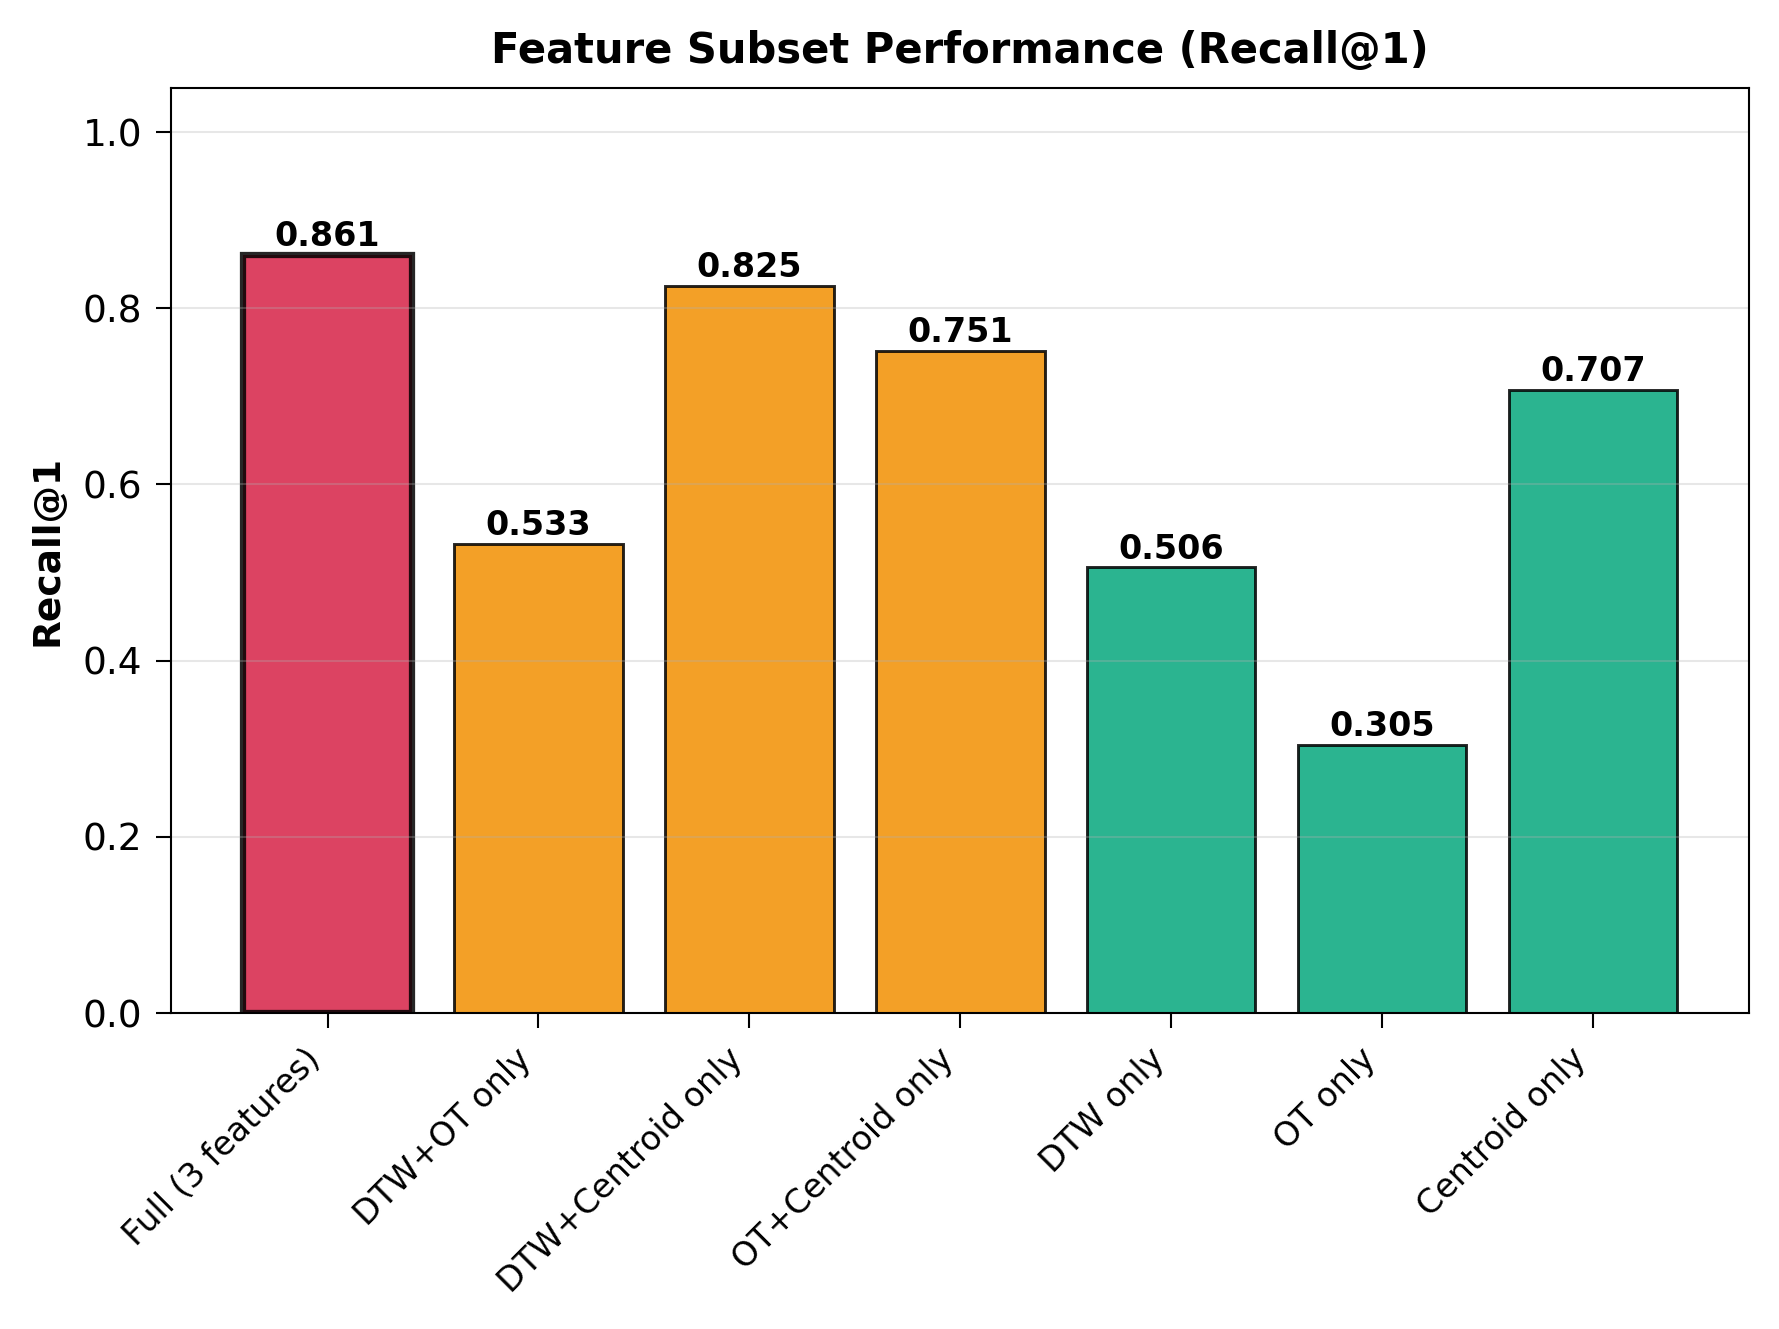

Saved: linear_feature_combination_analysis/core_features_performance_recall1.pdf


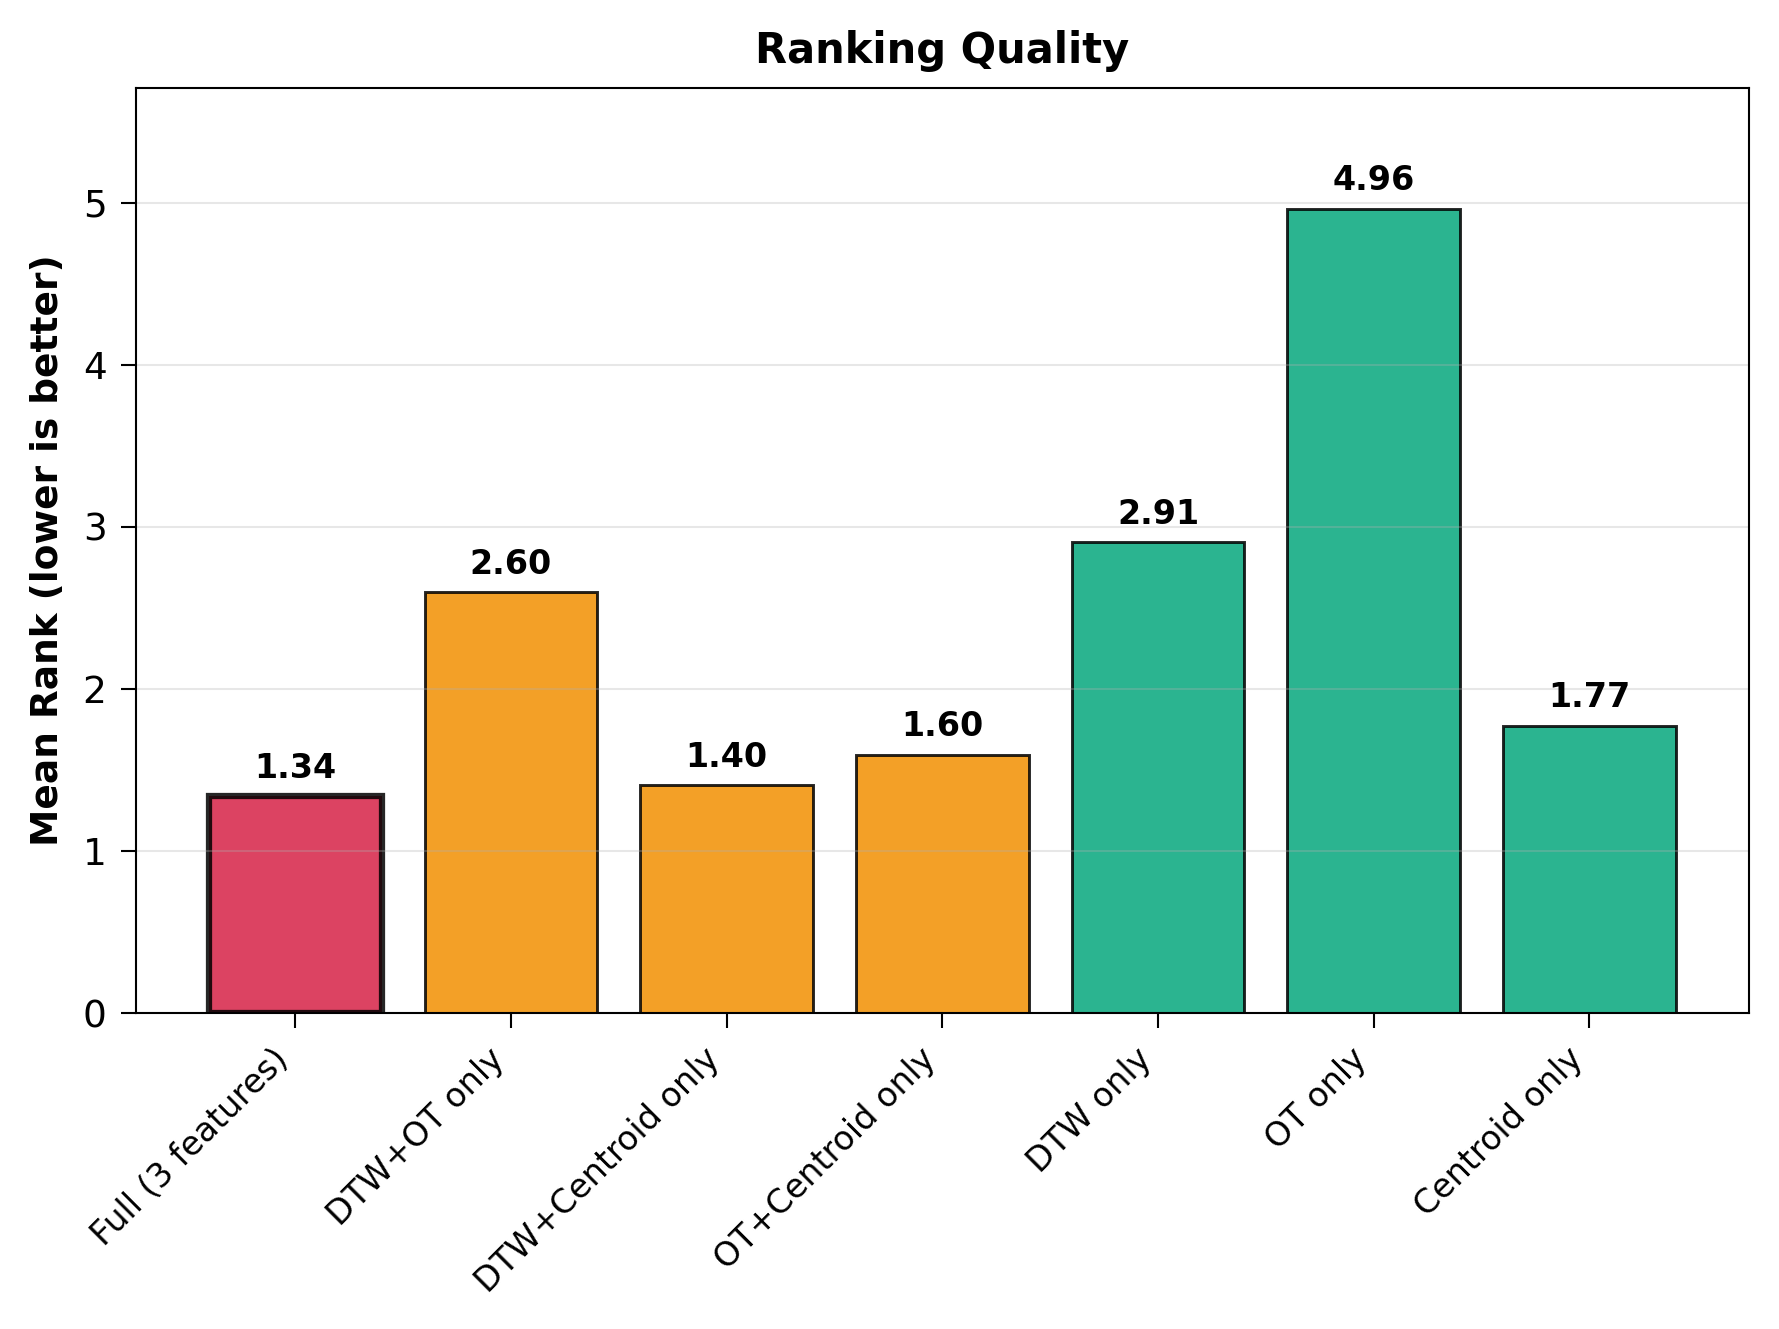

Saved: linear_feature_combination_analysis/core_features_performance_meanrank.pdf


In [35]:
print("\nGenerating visualizations...")
plot_core_features_performance(results_df, OUTPUT_DIR)

In [36]:
best = results_df.iloc[0]

print("\n" + "=" * 80)
print("BEST FEATURE COMBINATION")
print("=" * 80)
print(f"Features:   {best['features']}")
print(f"Recall@1:   {best['Recall@1']:.4f}")
print(f"Recall@3:   {best['Recall@3']:.4f}")
print(f"Recall@5:   {best['Recall@5']:.4f}")
print(f"Mean Rank:  {best['mean_rank']:.2f}")
print(f"MedianRank: {best['median_rank']:.2f}")
print("=" * 80)


BEST FEATURE COMBINATION
Features:   DTW+OT+Centroid
Recall@1:   0.8609
Recall@3:   0.9260
Recall@5:   0.9586
Mean Rank:  1.34
MedianRank: 1.00
